# QSAR DILI Prediction — ECFP4 + 7 Assay Features
**Closes the in vitro → in vivo gap.**

Same pipeline as `qsar_mito_dili_invivo_external_test.ipynb`:
- **Training**: Alloriginaldata (12,900 compounds, leakage-free)
- **External test**: DILI Goldstandard (1,096 compounds, held out)
- **Split**: 20% internal test → 80/20 train/val → downsample train to 1:1
- **Features A**: ECFP4 2048-bit (structure only)
- **Features B**: ECFP4 2048 + 7 assay bits = 2055-dim (structure + mechanism)
- **Models**: Random Forest, SVM, XGBoost — tuned on val AUC
- **Key question**: Does adding assay bits improve external DILI prediction?

In [8]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import copy, time

from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem, DataStructs
RDLogger.DisableLog('rdApp.*')

from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (roc_auc_score, roc_curve, average_precision_score,
                              confusion_matrix, classification_report,
                              precision_recall_curve)
from xgboost import XGBClassifier

SEED = 42
BASE = '/Users/yaminichitikela/Desktop/qsar casepase'
print('Imports OK')


Imports OK


---
## Step 1 — Data Loading & Label Assignment

In [9]:
def canon(s):
    try: m = Chem.MolFromSmiles(str(s)); return Chem.MolToSmiles(m) if m else None
    except: return None

def outcome_label(o):
    if o == 'Active':   return 1.0
    if o == 'Inactive': return 0.0
    return np.nan

def lut_from_csv(path):
    df = pd.read_csv(path, low_memory=False)
    smi_col = next(c for c in df.columns if 'SMILES' in c.upper())
    out_col = next(c for c in df.columns if 'OUTCOME' in c.upper())
    df['csmi'] = df[smi_col].apply(canon)
    df = df.dropna(subset=['csmi']).drop_duplicates('csmi')
    return dict(zip(df['csmi'], df[out_col].apply(outcome_label)))

# ── Training data (Alloriginaldata) ──────────────────────────────────────────
big = pd.read_csv(f'{BASE}/liver/Alloriginaldata_19911.csv')
big['csmi'] = big['smiles_r'].apply(canon)
big = big.dropna(subset=['csmi']).drop_duplicates('csmi').reset_index(drop=True)
big['label'] = big['TOXICITY'].astype(int)
print(f'Alloriginaldata raw: {len(big):,}  DILI+={big.label.sum()}  DILI-={(big.label==0).sum()}')

# ── External test: DILI Goldstandard (HELD OUT — never used in training/val) ─
df_gold = pd.read_csv(f'{BASE}/liver/DILI_Goldstandard_1111.csv')
df_gold['csmi'] = df_gold['smiles_r'].apply(canon)
df_gold = df_gold.dropna(subset=['csmi']).drop_duplicates('csmi').reset_index(drop=True)
df_gold['label'] = df_gold['TOXICITY'].astype(int)
print(f'Goldstandard:        {len(df_gold):,}  DILI+={df_gold.label.sum()}  DILI-={(df_gold.label==0).sum()}')

# Remove goldstandard overlap from training to prevent data leakage
gs_smis   = set(df_gold.csmi)
df = big[~big.csmi.isin(gs_smis)].copy().reset_index(drop=True)
print(f'\nTraining pool (leakage-free): {len(df):,}')
print(f'  DILI+: {(df.label==1).sum():,}  DILI-: {(df.label==0).sum():,}')
print(f'  Imbalance ratio: {(df.label==0).sum()/(df.label==1).sum():.1f}:1')


Alloriginaldata raw: 13,788  DILI+=4771  DILI-=9017
Goldstandard:        1,096  DILI+=708  DILI-=388

Training pool (leakage-free): 12,900
  DILI+: 4,217  DILI-: 8,683
  Imbalance ratio: 2.1:1


---
## Step 2 — Feature Engineering

**Feature A**: Morgan ECFP4 (2048 bits) — structure only  
**Feature B**: ECFP4 (2048) + 7 assay bits (2055-dim) — structure + mechanism

Assay bits: `1` if Active in assay, `0` if Inactive **or unknown** (conservative encoding)

In [27]:
# ── Load all 7 assay LUTs ────────────────────────────────────────────────────
_m = pd.read_excel(f'{BASE}/mito/AID_720635_cleaned.xlsx',
     usecols=['PUBCHEM_EXT_DATASOURCE_SMILES','PUBCHEM_ACTIVITY_OUTCOME'])
_m['csmi'] = _m['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(canon)
_m = _m.dropna(subset=['csmi']).drop_duplicates('csmi')
mito_lut = dict(zip(_m['csmi'], _m['PUBCHEM_ACTIVITY_OUTCOME'].apply(outcome_label)))

_c = pd.read_csv(f'{BASE}/caspase/combined_hepg2_casepase.csv',
     usecols=['PUBCHEM_EXT_DATASOURCE_SMILES','PUBCHEM_ACTIVITY_OUTCOME'])
_c['csmi'] = _c['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(canon)
_c = _c.dropna(subset=['csmi']).drop_duplicates('csmi')
casp_lut = dict(zip(_c['csmi'], _c['PUBCHEM_ACTIVITY_OUTCOME'].apply(outcome_label)))

bsep_lut  = lut_from_csv(f'{BASE}/liver/AID_686978_datatable.csv')
rm_lut    = lut_from_csv(f'{BASE}/liver/AID_743202_datatable.csv')
are_lut   = lut_from_csv(f'{BASE}/cleaned_datasets/AID_651741_datatable.csv')
tr_lut    = lut_from_csv(f'{BASE}/cleaned_datasets/AID_743067_datatable.csv')
pparg_lut = lut_from_csv(f'{BASE}/cleaned_datasets/AID_743140_datatable.csv')

ASSAY_LUTS = {
    'Mito (AID_720635)':      mito_lut,
    'Caspase (HepG2)':         casp_lut,
    'BSEP (AID_686978)':      bsep_lut,
    'React.Met (AID_743202)': rm_lut,
    'ARE-bla (AID_651741)':   are_lut,
    'TR antag (AID_743067)':  tr_lut,
    'PPARg (AID_743140)':     pparg_lut,
}
assay_names = list(ASSAY_LUTS.keys())

def smiles_to_ecfp4(smi, n_bits=2048):
    mol = Chem.MolFromSmiles(smi)
    if mol is None: return None
    fp  = AllChem.GetMorganFingerprintAsBitVect(mol, 2, nBits=n_bits)
    arr = np.zeros(n_bits, dtype=np.float32)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

def build_features(df_):
    """Returns X_ecfp (2048) and X_full (2055 = ECFP4 + 7 assay bits)."""
    ecfp_rows, assay_rows = [], []
    for smi in df_.csmi:
        fp = smiles_to_ecfp4(smi)
        if fp is None: fp = np.zeros(2048, dtype=np.float32)
        ecfp_rows.append(fp)
        abits = np.array([1.0 if ASSAY_LUTS[a].get(smi, np.nan) == 1.0 else 0.0
                          for a in assay_names], dtype=np.float32)
        assay_rows.append(abits)
    X_ecfp  = np.vstack(ecfp_rows)
    X_full  = np.hstack([X_ecfp, np.vstack(assay_rows)])
    return X_ecfp, X_full

print('Building training features...')
X_ecfp_all, X_full_all = build_features(df)
y_all = df.label.values
print(f'  ECFP4-only : {X_ecfp_all.shape}')
print(f'  ECFP4+Assay: {X_full_all.shape}')
print(f'  Compounds with >=1 assay Active: {(X_full_all[:,2048:].sum(1)>0).mean()*100:.1f}%')

print('\nBuilding goldstandard features...')
X_ecfp_gs, X_full_gs = build_features(df_gold)
y_gs = df_gold.label.values
print(f'  ECFP4-only : {X_ecfp_gs.shape}')
print(f'  ECFP4+Assay: {X_full_gs.shape}')
print(f'  Goldstandard with >=1 assay Active: {(X_full_gs[:,2048:].sum(1)>0).mean()*100:.1f}%')


Building training features...
  ECFP4-only : (12900, 2048)
  ECFP4+Assay: (12900, 2055)
  Compounds with >=1 assay Active: 11.8%

Building goldstandard features...
  ECFP4-only : (1096, 2048)
  ECFP4+Assay: (1096, 2055)
  Goldstandard with >=1 assay Active: 10.5%


---
## Step 3 — 80/20/20 Split + Downsampling

Exact same procedure as mito QSAR:
1. 20% internal test holdout (stratified)
2. 80/20 train/val from remaining 80%
3. Downsample train to **1:1** (DILI+ : DILI-) — train only, val/test stay imbalanced

Split summary
  Train (balanced 1:1): 5,398  DILI+=2699  DILI-=2699
  Val   (imbalanced)  : 2,064    DILI+=675  DILI-=1389
  Test  (imbalanced)  : 2,580   DILI+=843  DILI-=1737
  External (Goldstd)  : 1,096   DILI+=708  DILI-=388


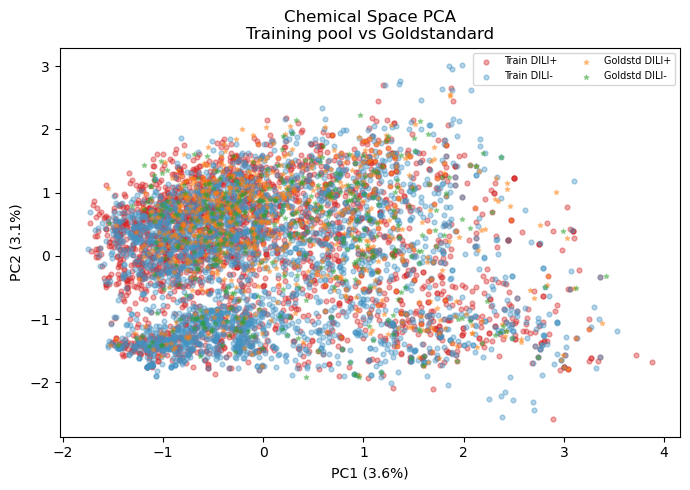

In [4]:
# ── 20% internal test split (stratified) ─────────────────────────────────────
idx_all = np.arange(len(y_all))
idx_pool, idx_test = train_test_split(idx_all, test_size=0.20,
                                       stratify=y_all, random_state=SEED)

# Both feature sets use same indices
X_ecfp_pool,  X_ecfp_test  = X_ecfp_all[idx_pool],  X_ecfp_all[idx_test]
X_full_pool,  X_full_test   = X_full_all[idx_pool],  X_full_all[idx_test]
y_pool, y_test = y_all[idx_pool], y_all[idx_test]

# ── 80/20 train/val from pool ─────────────────────────────────────────────────
pool_idx = np.arange(len(y_pool))
tr_idx, val_idx = train_test_split(pool_idx, test_size=0.20,
                                    stratify=y_pool, random_state=SEED)

X_ecfp_tr_raw, X_ecfp_val = X_ecfp_pool[tr_idx], X_ecfp_pool[val_idx]
X_full_tr_raw, X_full_val  = X_full_pool[tr_idx], X_full_pool[val_idx]
y_tr_raw, y_val = y_pool[tr_idx], y_pool[val_idx]

# ── Downsample TRAIN only to 1:1 ─────────────────────────────────────────────
act_idx = np.where(y_tr_raw == 1)[0]
ina_idx = np.where(y_tr_raw == 0)[0]
rng = np.random.RandomState(SEED)
sampled_ina = rng.choice(ina_idx, size=len(act_idx), replace=False)
bal_idx = np.concatenate([act_idx, sampled_ina])
rng.shuffle(bal_idx)

X_ecfp_train, X_full_train = X_ecfp_tr_raw[bal_idx], X_full_tr_raw[bal_idx]
y_train = y_tr_raw[bal_idx]

print('Split summary')
print(f'  Train (balanced 1:1): {len(y_train):,}  DILI+={(y_train==1).sum()}  DILI-={(y_train==0).sum()}')
print(f'  Val   (imbalanced)  : {len(y_val):,}    DILI+={(y_val==1).sum()}  DILI-={(y_val==0).sum()}')
print(f'  Test  (imbalanced)  : {len(y_test):,}   DILI+={(y_test==1).sum()}  DILI-={(y_test==0).sum()}')
print(f'  External (Goldstd)  : {len(y_gs):,}   DILI+={(y_gs==1).sum()}  DILI-={(y_gs==0).sum()}')

# ── Chemical Space PCA ────────────────────────────────────────────────────────
from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=SEED)
pca.fit(X_ecfp_train)
tr_p = pca.transform(X_ecfp_train)
va_p = pca.transform(X_ecfp_val)
te_p = pca.transform(X_ecfp_test)
gs_p = pca.transform(X_ecfp_gs)

fig, ax = plt.subplots(figsize=(7,5))
for pts, lbl, col, mrk, z in [
    (tr_p[y_train==1], 'Train DILI+',    '#d62728', 'o', 2),
    (tr_p[y_train==0], 'Train DILI-',    '#4393c3', 'o', 2),
    (gs_p[y_gs==1],    'Goldstd DILI+',  '#ff7f0e', '*', 3),
    (gs_p[y_gs==0],    'Goldstd DILI-',  '#2ca02c', '*', 3),
]:
    ax.scatter(pts[:,0], pts[:,1], c=col, marker=mrk, s=12, alpha=0.4, label=lbl, zorder=z)
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
ax.set_title('Chemical Space PCA\nTraining pool vs Goldstandard')
ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.savefig(f'{BASE}/combined/qsar_dili_pca.png', dpi=150, bbox_inches='tight')
plt.show()


---
## Step 4 — Evaluation Helper

In [5]:
METRIC_COLS = ['Model','Features','CPT','Sensitivity','Specificity','CCR','ROC-AUC','AP']

def evaluate(y_true, y_prob, name, feat_label, cpt=0.5):
    y_pred = (y_prob >= cpt).astype(int)
    tn,fp,fn,tp = confusion_matrix(y_true, y_pred).ravel()
    sens = tp/(tp+fn) if (tp+fn)>0 else 0
    spec = tn/(tn+fp) if (tn+fp)>0 else 0
    return {
        'Model'      : name,
        'Features'   : feat_label,
        'CPT'        : cpt,
        'Sensitivity': round(sens*100, 1),
        'Specificity': round(spec*100, 1),
        'CCR'        : round((sens+spec)/2*100, 1),
        'ROC-AUC'    : round(roc_auc_score(y_true, y_prob), 4),
        'AP'         : round(average_precision_score(y_true, y_prob), 4),
        'TP':tp,'TN':tn,'FP':fp,'FN':fn,
    }
print('Evaluation helper ready.')


Evaluation helper ready.


---
## Step 5 — Classical ML: Hyperparameter Tuning

Train on balanced training set → tune on (imbalanced) val set by **ROC-AUC** → eval on internal test + goldstandard.

Each model trained **twice**: once on ECFP4-only, once on ECFP4+Assay.

In [6]:
rf_grid = ParameterGrid({
    'n_estimators'    : [300, 500],
    'max_features'    : ['sqrt', 0.3],
    'min_samples_leaf': [1, 3],
    'max_depth'       : [None, 20],
})

results = {}
for feat_label, X_tr, X_va in [('ECFP4-only',  X_ecfp_train, X_ecfp_val),
                                 ('ECFP4+Assay', X_full_train, X_full_val)]:
    best_auc, best_clf, best_p = 0, None, {}
    print(f'RF [{feat_label}]: {len(rf_grid)} configs...', end='')
    for p in rf_grid:
        clf = RandomForestClassifier(**p, class_weight='balanced',
                                      n_jobs=-1, random_state=SEED)
        clf.fit(X_tr, y_train)
        auc = roc_auc_score(y_val, clf.predict_proba(X_va)[:,1])
        if auc > best_auc: best_auc, best_clf, best_p = auc, clf, p
    results[('RF', feat_label)] = best_clf
    print(f'  best val AUC={best_auc:.4f}  params={best_p}')

best_rf_ecfp = results[('RF','ECFP4-only')]
best_rf_full = results[('RF','ECFP4+Assay')]


RF [ECFP4-only]: 16 configs...  best val AUC=0.7364  params={'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'n_estimators': 500}
RF [ECFP4+Assay]: 16 configs...  best val AUC=0.7429  params={'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'n_estimators': 500}


In [11]:
svm_grid = ParameterGrid({
    'C'    : [1, 10, 50],
    'gamma': ['scale', 0.01, 0.001],
})

for feat_label, X_tr, X_va in [('ECFP4-only',  X_ecfp_train, X_ecfp_val),
                                 ('ECFP4+Assay', X_full_train, X_full_val)]:
    best_auc, best_clf, best_p = 0, None, {}
    print(f'SVM [{feat_label}]: {len(svm_grid)} configs...', end='')
    for p in svm_grid:
        clf = SVC(**p, kernel='rbf', class_weight='balanced',
                   probability=True, random_state=SEED)
        clf.fit(X_tr, y_train)
        auc = roc_auc_score(y_val, clf.predict_proba(X_va)[:,1])
        if auc > best_auc: best_auc, best_clf, best_p = auc, clf, p
    results[('SVM', feat_label)] = best_clf
    print(f'  best val AUC={best_auc:.4f}  params={best_p}')

best_svm_ecfp = results[('SVM','ECFP4-only')]
best_svm_full = results[('SVM','ECFP4+Assay')]


SVM [ECFP4-only]: 9 configs...  best val AUC=0.7159  params={'C': 1, 'gamma': 'scale'}
SVM [ECFP4+Assay]: 9 configs...  best val AUC=0.7228  params={'C': 1, 'gamma': 'scale'}


In [12]:
sw = (y_train==0).sum() / (y_train==1).sum()
xgb_grid = ParameterGrid({
    'n_estimators' : [300, 500],
    'max_depth'    : [4, 6, 8],
    'learning_rate': [0.05, 0.1],
    'subsample'    : [0.8],
    'colsample_bytree': [0.8],
})

for feat_label, X_tr, X_va in [('ECFP4-only',  X_ecfp_train, X_ecfp_val),
                                 ('ECFP4+Assay', X_full_train, X_full_val)]:
    best_auc, best_clf, best_p = 0, None, {}
    print(f'XGB [{feat_label}]: {len(xgb_grid)} configs...', end='')
    for p in xgb_grid:
        clf = XGBClassifier(**p, scale_pos_weight=sw, eval_metric='logloss',
                             use_label_encoder=False, random_state=SEED, n_jobs=-1)
        clf.fit(X_tr, y_train)
        auc = roc_auc_score(y_val, clf.predict_proba(X_va)[:,1])
        if auc > best_auc: best_auc, best_clf, best_p = auc, clf, p
    results[('XGB', feat_label)] = best_clf
    print(f'  best val AUC={best_auc:.4f}  params={best_p}')

best_xgb_ecfp = results[('XGB','ECFP4-only')]
best_xgb_full = results[('XGB','ECFP4+Assay')]


XGB [ECFP4-only]: 12 configs...  best val AUC=0.7368  params={'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 6, 'n_estimators': 300, 'subsample': 0.8}
XGB [ECFP4+Assay]: 12 configs...  best val AUC=0.7410  params={'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 8, 'n_estimators': 300, 'subsample': 0.8}


---
## Step 6 — Internal Test + External Goldstandard Evaluation

In [13]:
model_pairs = [
    ('Random Forest', best_rf_ecfp,  best_rf_full),
    ('SVM',           best_svm_ecfp, best_svm_full),
    ('XGBoost',       best_xgb_ecfp, best_xgb_full),
]

rows_int, rows_ext = [], []

for name, clf_e, clf_f in model_pairs:
    for feat_label, clf, X_te, X_ex in [
        ('ECFP4-only',  clf_e, X_ecfp_test, X_ecfp_gs),
        ('ECFP4+Assay', clf_f, X_full_test, X_full_gs),
    ]:
        p_te = clf.predict_proba(X_te)[:,1]
        p_ex = clf.predict_proba(X_ex)[:,1]
        for cpt in [0.5, 0.8]:
            rows_int.append(evaluate(y_test, p_te, name, feat_label, cpt))
            rows_ext.append(evaluate(y_gs,   p_ex, name, feat_label, cpt))

# Consensus (average RF+SVM+XGB per feature set)
for feat_label, clfs, X_te, X_ex in [
    ('ECFP4-only',  [best_rf_ecfp, best_svm_ecfp, best_xgb_ecfp], X_ecfp_test, X_ecfp_gs),
    ('ECFP4+Assay', [best_rf_full, best_svm_full, best_xgb_full],  X_full_test, X_full_gs),
]:
    p_te = np.mean([c.predict_proba(X_te)[:,1] for c in clfs], axis=0)
    p_ex = np.mean([c.predict_proba(X_ex)[:,1] for c in clfs], axis=0)
    for cpt in [0.5, 0.8]:
        rows_int.append(evaluate(y_test, p_te, 'Consensus', feat_label, cpt))
        rows_ext.append(evaluate(y_gs,   p_ex, 'Consensus', feat_label, cpt))

df_int = pd.DataFrame(rows_int)
df_ext = pd.DataFrame(rows_ext)

print('=== Internal Test (CPT=0.5) ===')
display(df_int[df_int.CPT==0.5][METRIC_COLS].set_index(['Model','Features']).sort_values('ROC-AUC', ascending=False))

print('\n=== External Goldstandard (CPT=0.5) ===')
display(df_ext[df_ext.CPT==0.5][METRIC_COLS].set_index(['Model','Features']).sort_values('ROC-AUC', ascending=False))


=== Internal Test (CPT=0.5) ===


CPT  Sensitivity  Specificity   CCR  ROC-AUC  \
Model         Features                                                    
Random Forest ECFP4+Assay  0.5         67.5         69.8  68.6   0.7428   
Consensus     ECFP4+Assay  0.5         65.4         69.9  67.6   0.7414   
XGBoost       ECFP4+Assay  0.5         64.7         69.7  67.2   0.7378   
Random Forest ECFP4-only   0.5         67.6         68.3  67.9   0.7348   
Consensus     ECFP4-only   0.5         66.8         67.9  67.3   0.7348   
XGBoost       ECFP4-only   0.5         66.9         65.5  66.2   0.7271   
SVM           ECFP4+Assay  0.5         65.7         66.6  66.1   0.7198   
              ECFP4-only   0.5         66.7         65.5  66.1   0.7143   

                               AP  
Model         Features             
Random Forest ECFP4+Assay  0.5721  
Consensus     ECFP4+Assay  0.5683  
XGBoost       ECFP4+Assay  0.5548  
Random Forest ECFP4-only   0.5669  
Consensus     ECFP4-only   0.5684  
XGBoost       ECFP4-only   0.5546  
SVM           ECFP4+Assay  0.5477  
              ECFP4-only   0.5481


=== External Goldstandard (CPT=0.5) ===


CPT  Sensitivity  Specificity   CCR  ROC-AUC  \
Model         Features                                                    
Random Forest ECFP4-only   0.5         65.3         60.6  62.9   0.6820   
              ECFP4+Assay  0.5         64.4         63.9  64.2   0.6785   
Consensus     ECFP4+Assay  0.5         64.0         63.7  63.8   0.6781   
              ECFP4-only   0.5         64.8         61.6  63.2   0.6771   
SVM           ECFP4-only   0.5         64.3         59.3  61.8   0.6760   
              ECFP4+Assay  0.5         62.4         61.3  61.9   0.6745   
XGBoost       ECFP4+Assay  0.5         64.8         59.8  62.3   0.6650   
              ECFP4-only   0.5         65.8         55.9  60.9   0.6571   

                               AP  
Model         Features             
Random Forest ECFP4-only   0.7850  
              ECFP4+Assay  0.7803  
Consensus     ECFP4+Assay  0.7770  
              ECFP4-only   0.7750  
SVM           ECFP4-only   0.7717  
              ECFP4+Assay  0.7749  
XGBoost       ECFP4+Assay  0.7620  
              ECFP4-only   0.7514

---
## Step 6 — Graph Neural Networks (GCN / GAT / GIN / GraphSAGE)

**Same architecture as `qsar_mito_dili_invivo_external_test.ipynb`:**
```
SMILES → Atom/Bond features (27-dim / 6-dim)
  → Linear projection
  → 3 × [Conv + BatchNorm + ReLU + Dropout + Residual]
  → GlobalMeanPool  ← graph-level embedding (hidden-dim)
  → Concat 7 assay bits  ← molecule-level, not atom-level
  → MLP head [hidden+7 → hidden/2 → 1]
  → BCEWithLogitsLoss
```
Tuned: `hidden`, `n_layers`, `dropout`, `lr` — selected by **val ROC-AUC**.

In [16]:
import torch
import torch.nn as nn
from torch_geometric.nn import GCNConv, GATConv, GINConv, SAGEConv, global_mean_pool
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader as GeoLoader

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ATOM_SYMBOLS = [6,7,8,16,9,15,17,35,53]  # C N O S F P Cl Br I

def one_hot(val, choices):
    v = [0]*len(choices)
    try: v[choices.index(val)] = 1
    except ValueError: pass
    return v

def atom_feat(atom):
    return (one_hot(atom.GetAtomicNum(), ATOM_SYMBOLS) + [1]  # other
            + one_hot(atom.GetDegree(), [0,1,2,3,4,5])
            + [atom.GetFormalCharge()]
            + one_hot(int(atom.GetHybridization()), [2,3,4,5])  # SP SP2 SP3 SP3D
            + [int(atom.GetIsAromatic()), int(atom.IsInRing()),
               atom.GetTotalNumHs(), atom.GetMass()/100.0])

def bond_feat(bond):
    bt = bond.GetBondTypeAsDouble()
    return ([int(bt==1.0), int(bt==2.0), int(bt==3.0), int(bt==1.5)]
            + [int(bond.GetIsConjugated()), int(bond.IsInRing())])

ATOM_DIM = len(atom_feat(Chem.MolFromSmiles('C').GetAtomWithIdx(0)))
print(f'Atom feature dim: {ATOM_DIM}  Device: {DEVICE}')

def mol_to_graph(smi, label, assay_bits):
    mol = Chem.MolFromSmiles(smi)
    if mol is None: return None
    x  = torch.tensor([atom_feat(a) for a in mol.GetAtoms()], dtype=torch.float)
    ei, ea = [], []
    for bond in mol.GetBonds():
        i,j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        bf  = bond_feat(bond)
        ei += [[i,j],[j,i]]; ea += [bf,bf]
    if not ei:
        ei = torch.zeros((2,0), dtype=torch.long)
        ea = torch.zeros((0,6), dtype=torch.float)
    else:
        ei = torch.tensor(ei, dtype=torch.long).t().contiguous()
        ea = torch.tensor(ea, dtype=torch.float)
    ab = torch.tensor(assay_bits, dtype=torch.float).unsqueeze(0)  # (1, 7)
    return Data(x=x, edge_index=ei, edge_attr=ea,
                y=torch.tensor([label], dtype=torch.float),
                assay=ab)

# Build graph datasets
print('Building graphs...')
N_ASSAY = len(assay_names)
graphs_all, valid_idx = [], []
for i, (smi, lbl) in enumerate(zip(df.csmi, y_all)):
    abits = X_full_all[i, 2048:]   # 7 assay bits from prebuilt array
    g = mol_to_graph(smi, lbl, abits)
    if g is not None:
        graphs_all.append(g); valid_idx.append(i)

valid_idx = np.array(valid_idx)
print(f'Valid graphs: {len(graphs_all):,} / {len(df):,}')

# Build goldstandard graphs
graphs_gs = []
for i, (smi, lbl) in enumerate(zip(df_gold.csmi, y_gs)):
    abits = X_full_gs[i, 2048:]
    g = mol_to_graph(smi, lbl, abits)
    if g is not None: graphs_gs.append(g)
print(f'Goldstandard graphs: {len(graphs_gs):,}')


Atom feature dim: 25  Device: cpu
Building graphs...
Valid graphs: 12,900 / 12,900
Goldstandard graphs: 1,096


In [17]:
# Use same indices as classical ML (remap to valid_idx subset)
# Reindex: only keep graphs that exist in valid_idx
idx_in_valid = {orig: new for new, orig in enumerate(valid_idx)}

def remap(idx_arr):
    """Keep only indices that have valid graphs, return new positions."""
    kept = [idx_in_valid[i] for i in idx_arr if i in idx_in_valid]
    return kept

tr_g_idx   = remap(np.where(np.isin(np.arange(len(y_all)), idx_pool[tr_idx][bal_idx]))[0])
val_g_idx  = remap(np.where(np.isin(np.arange(len(y_all)), idx_pool[val_idx]))[0])
test_g_idx = remap(np.where(np.isin(np.arange(len(y_all)), idx_test))[0])

graphs_train_g = [graphs_all[i] for i in tr_g_idx]
graphs_val_g   = [graphs_all[i] for i in val_g_idx]
graphs_test_g  = [graphs_all[i] for i in test_g_idx]

BATCH = 64
train_loader = GeoLoader(graphs_train_g, batch_size=BATCH, shuffle=True)
val_loader   = GeoLoader(graphs_val_g,   batch_size=BATCH, shuffle=False)
test_loader  = GeoLoader(graphs_test_g,  batch_size=BATCH, shuffle=False)
gs_loader    = GeoLoader(graphs_gs,      batch_size=BATCH, shuffle=False)

ytrain_g = np.array([g.y.item() for g in graphs_train_g])
yval_g   = np.array([g.y.item() for g in graphs_val_g])
ytest_g  = np.array([g.y.item() for g in graphs_test_g])
ygs_g    = np.array([g.y.item() for g in graphs_gs])

pos_w = torch.tensor([(ytrain_g==0).sum()/(ytrain_g==1).sum()]).to(DEVICE)
print(f'GNN Train:{len(graphs_train_g)}  Val:{len(graphs_val_g)}  Test:{len(graphs_test_g)}  GS:{len(graphs_gs)}')
print(f'Positive weight: {pos_w.item():.2f}')


GNN Train:5398  Val:2064  Test:2580  GS:1096
Positive weight: 1.00


In [18]:
class MolGNN(nn.Module):
    """GNN for DILI prediction. Assay bits injected at graph level (after pooling)."""
    def __init__(self, in_dim, hidden=128, n_layers=3, dropout=0.3,
                 conv_type='GCN', heads=4, n_assay=7):
        super().__init__()
        self.conv_type = conv_type
        self.n_layers  = n_layers
        self.dropout   = dropout
        self.input_proj = nn.Linear(in_dim, hidden)

        self.convs = nn.ModuleList()
        self.bns   = nn.ModuleList()
        for _ in range(n_layers):
            if conv_type == 'GCN':
                self.convs.append(GCNConv(hidden, hidden))
            elif conv_type == 'GAT':
                self.convs.append(GATConv(hidden, hidden//heads, heads=heads, dropout=dropout))
            elif conv_type == 'GIN':
                mlp = nn.Sequential(nn.Linear(hidden,hidden), nn.ReLU(), nn.Linear(hidden,hidden))
                self.convs.append(GINConv(mlp))
            elif conv_type == 'SAGE':
                self.convs.append(SAGEConv(hidden, hidden))
            self.bns.append(nn.BatchNorm1d(hidden))

        # MLP head: graph embedding + assay bits -> DILI logit
        self.mlp = nn.Sequential(
            nn.Linear(hidden + n_assay, hidden // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden // 2, 1)
        )

    def forward(self, x, edge_index, batch, assay=None):
        x = self.input_proj(x)
        for conv, bn in zip(self.convs, self.bns):
            h = conv(x, edge_index)
            h = bn(h)
            h = torch.relu(h)
            h = torch.dropout(h, self.dropout, self.training)
            x = x + h  # residual
        g = global_mean_pool(x, batch)   # (batch_size, hidden)
        # Inject assay bits at graph level
        if assay is not None:
            ab = assay.view(g.size(0), -1)  # (batch_size, n_assay)
            g  = torch.cat([g, ab], dim=1)
        return self.mlp(g).squeeze(-1)

def gnn_train_epoch(model, loader, optimizer, criterion):
    model.train(); total_loss = 0
    for batch in loader:
        batch = batch.to(DEVICE); optimizer.zero_grad()
        logits = model(batch.x, batch.edge_index, batch.batch,
                       assay=batch.assay if hasattr(batch,'assay') else None)
        loss = criterion(logits, batch.y)
        loss.backward(); optimizer.step()
        total_loss += loss.item() * batch.num_graphs
    return total_loss / len(loader.dataset)

def gnn_eval(model, loader):
    model.eval(); probs, labels = [], []
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(DEVICE)
            logits = model(batch.x, batch.edge_index, batch.batch,
                           assay=batch.assay if hasattr(batch,'assay') else None)
            probs.extend(torch.sigmoid(logits).cpu().numpy())
            labels.extend(batch.y.cpu().numpy())
    return np.array(probs), np.array(labels)

print('MolGNN architecture ready.')


MolGNN architecture ready.


In [19]:
GNN_CONFIGS = {
    'GCN' : [
        {'hidden':128, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':256, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':128, 'n_layers':4, 'dropout':0.4, 'lr':0.0005},
    ],
    'GAT' : [
        {'hidden':128, 'n_layers':3, 'dropout':0.3, 'lr':0.001,  'heads':4},
        {'hidden':128, 'n_layers':3, 'dropout':0.4, 'lr':0.0005, 'heads':8},
    ],
    'GIN' : [
        {'hidden':128, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':256, 'n_layers':3, 'dropout':0.4, 'lr':0.0005},
    ],
    'SAGE': [
        {'hidden':128, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':256, 'n_layers':4, 'dropout':0.4, 'lr':0.0005},
    ],
}

EPOCHS   = 100
PATIENCE = 20
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_w)

gnn_best_models  = {}
gnn_best_configs = {}
gnn_best_val_auc = {}
gnn_history      = {}

for arch, configs in GNN_CONFIGS.items():
    best_auc, best_state, best_cfg = 0, None, None
    tr_hist, va_hist = [], []
    for cfg in configs:
        model = MolGNN(ATOM_DIM, hidden=cfg['hidden'], n_layers=cfg['n_layers'],
                       dropout=cfg['dropout'], conv_type=arch,
                       heads=cfg.get('heads',4), n_assay=N_ASSAY).to(DEVICE)
        opt   = torch.optim.Adam(model.parameters(), lr=cfg['lr'])
        sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, patience=8, factor=0.5)
        no_improve = 0
        for epoch in range(EPOCHS):
            loss = gnn_train_epoch(model, train_loader, opt, criterion)
            vp, vl = gnn_eval(model, val_loader)
            va = roc_auc_score(vl, vp)
            sched.step(1 - va)
            tr_hist.append(roc_auc_score(ytrain_g,
                gnn_eval(model, train_loader)[0]))
            va_hist.append(va)
            if va > best_auc:
                best_auc, best_state, best_cfg = va, copy.deepcopy(model.state_dict()), cfg
                no_improve = 0
            else:
                no_improve += 1
            if no_improve >= PATIENCE:
                break
        print(f'  {arch} cfg={cfg}  best val AUC={best_auc:.4f}')

    gnn_best_models[arch]  = best_state
    gnn_best_configs[arch] = best_cfg
    gnn_best_val_auc[arch] = best_auc
    gnn_history[arch]      = (tr_hist, va_hist)
    print(f'{arch} done — best val AUC={best_auc:.4f}  cfg={best_cfg}')


  GCN cfg={'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001}  best val AUC=0.7598
  GCN cfg={'hidden': 256, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001}  best val AUC=0.7598
  GCN cfg={'hidden': 128, 'n_layers': 4, 'dropout': 0.4, 'lr': 0.0005}  best val AUC=0.7598
GCN done — best val AUC=0.7598  cfg={'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001}
  GAT cfg={'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  best val AUC=0.7548
  GAT cfg={'hidden': 128, 'n_layers': 3, 'dropout': 0.4, 'lr': 0.0005, 'heads': 8}  best val AUC=0.7548
GAT done — best val AUC=0.7548  cfg={'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}
  GIN cfg={'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001}  best val AUC=0.7613
  GIN cfg={'hidden': 256, 'n_layers': 3, 'dropout': 0.4, 'lr': 0.0005}  best val AUC=0.7613
GIN done — best val AUC=0.7613  cfg={'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001}
  SAGE cfg={'hidden': 128, 'n_layers

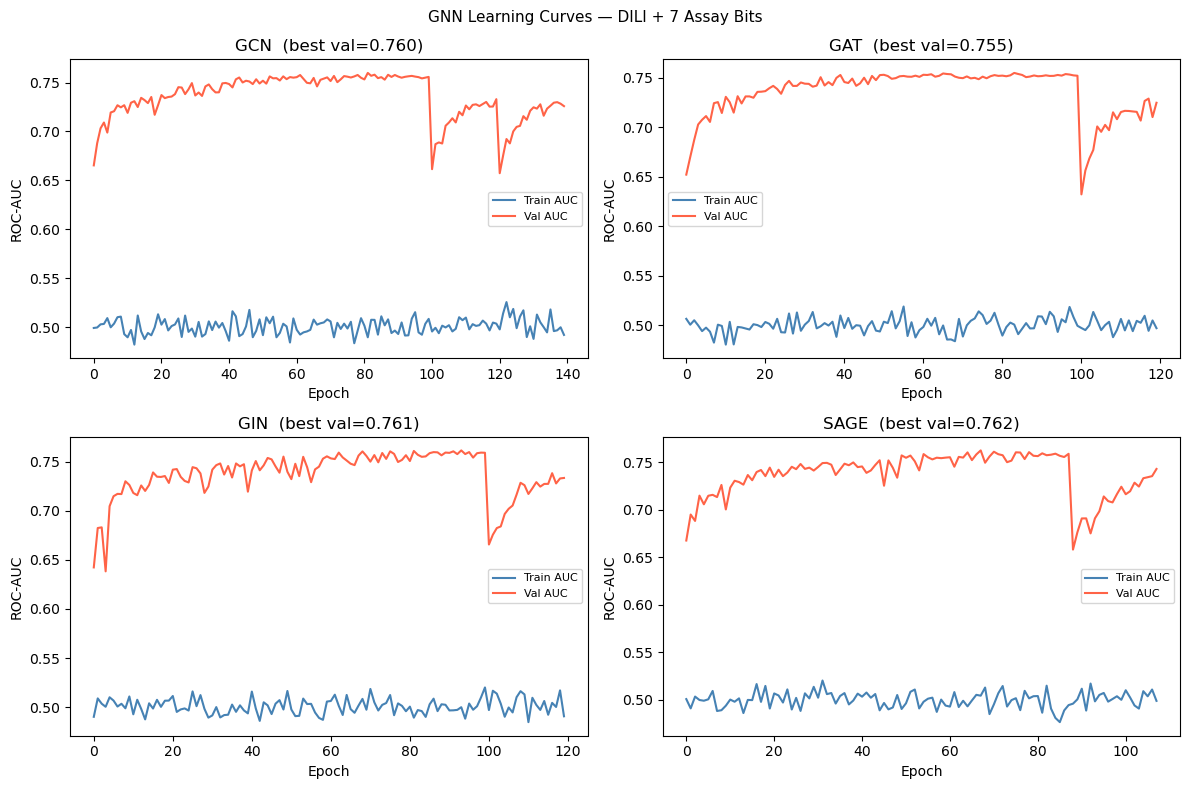

Model       Sens%  Spec%   CCR%     AUC      AP
──────────────────────────────────────────────────
GCN          74.0   47.9   61.0   0.637  0.7364
GAT          72.3   46.9   59.6  0.6317  0.7396
GIN          69.2   50.8   60.0  0.6418  0.7466
SAGE         78.2   37.6   57.9  0.6223  0.7325
GNN-Consensus   75.7   45.1   60.4  0.6422  0.7452


In [20]:
# ── Learning curves ──────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, arch in zip(axes.ravel(), ['GCN','GAT','GIN','SAGE']):
    if arch in gnn_history:
        tr, va = gnn_history[arch]
        ax.plot(tr, label='Train AUC', color='steelblue')
        ax.plot(va, label='Val AUC',   color='tomato')
        ax.set_title(f'{arch}  (best val={gnn_best_val_auc[arch]:.3f})')
        ax.set_xlabel('Epoch'); ax.set_ylabel('ROC-AUC')
        ax.legend(fontsize=8)
plt.suptitle('GNN Learning Curves — DILI + 7 Assay Bits', fontsize=11)
plt.tight_layout()
plt.savefig(f'{BASE}/combined/qsar_dili_gnn_curves.png', dpi=150, bbox_inches='tight')
plt.show()

# ── GNN goldstandard evaluation ───────────────────────────────────────────────
gnn_probs_gs = {}
rows_gnn = []
print(f'{"Model":<10} {"Sens%":>6} {"Spec%":>6} {"CCR%":>6} {"AUC":>7} {"AP":>7}')
print('─'*50)
for arch, state in gnn_best_models.items():
    cfg   = gnn_best_configs[arch]
    model = MolGNN(ATOM_DIM, hidden=cfg['hidden'], n_layers=cfg['n_layers'],
                   dropout=cfg['dropout'], conv_type=arch,
                   heads=cfg.get('heads',4), n_assay=N_ASSAY).to(DEVICE)
    model.load_state_dict(state)
    probs, _ = gnn_eval(model, gs_loader)
    gnn_probs_gs[arch] = probs
    r = evaluate(ygs_g, probs, arch, 'GNN+Assay')
    rows_gnn.append(r)
    print(f'{arch:<10} {r["Sensitivity"]:>6} {r["Specificity"]:>6} {r["CCR"]:>6} {r["ROC-AUC"]:>7} {r["AP"]:>7}')

# GNN consensus
gnn_cons = np.mean(list(gnn_probs_gs.values()), axis=0)
r = evaluate(ygs_g, gnn_cons, 'GNN-Consensus', 'GNN+Assay')
rows_gnn.append(r)
print(f'{"GNN-Consensus":<10} {r["Sensitivity"]:>6} {r["Specificity"]:>6} {r["CCR"]:>6} {r["ROC-AUC"]:>7} {r["AP"]:>7}')


=== FINAL GOLDSTANDARD SUMMARY ===


,Model,Features,Sensitivity,Specificity,CCR,ROC-AUC,AP
0,Random Forest,ECFP4-only,65.3,60.6,62.9,0.6820,0.7850
1,Random Forest,ECFP4+Assay,64.4,63.9,64.2,0.6785,0.7803
2,Consensus-Classical,ECFP4+Assay,64.0,63.7,63.8,0.6781,0.7770
3,Consensus-Classical,ECFP4-only,64.8,61.6,63.2,0.6771,0.7750
4,SVM,ECFP4-only,64.3,59.3,61.8,0.6760,0.7717
5,SVM,ECFP4+Assay,62.4,61.3,61.9,0.6745,0.7749
6,XGBoost,ECFP4+Assay,64.8,59.8,62.3,0.6650,0.7620
7,XGBoost,ECFP4-only,65.8,55.9,60.9,0.6571,0.7514
8,Full Consensus(Classical+GNN),ECFP4+Assay+GNN,75.6,46.6,61.1,0.6539,0.7546
9,Consensus-GNN,GNN+Assay,75.7,45.1,60.4,0.6422,0.7452


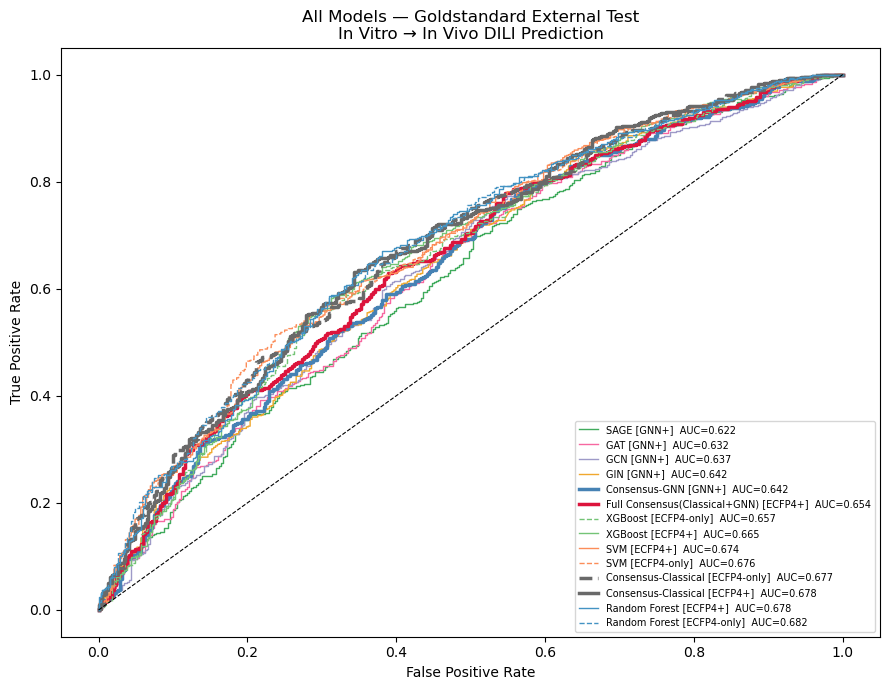

Saved → qsar_dili_roc_all.png


In [23]:
# ── Step 7 header already used — rename to Step 8 ────────────────────────────
# ── Full Consensus: Classical (ECFP4+Assay) + all 4 GNNs ─────────────────────
cl_probs_full_gs = np.mean([
    results[('RF','ECFP4+Assay')].predict_proba(X_full_gs)[:,1],
    results[('SVM','ECFP4+Assay')].predict_proba(X_full_gs)[:,1],
    results[('XGB','ECFP4+Assay')].predict_proba(X_full_gs)[:,1],
], axis=0)

all_probs_gs = list(gnn_probs_gs.values()) + [cl_probs_full_gs]
full_cons    = np.mean(all_probs_gs, axis=0)
r_full = evaluate(y_gs, full_cons, 'Full Consensus(Classical+GNN)', 'ECFP4+Assay+GNN')

print('=== FINAL GOLDSTANDARD SUMMARY ===')
# Collect all rows
all_rows = []
for nm,mk in [('Random Forest','RF'),('SVM','SVM'),('XGBoost','XGB')]:
    for fl,Xe in [('ECFP4-only',X_ecfp_gs),('ECFP4+Assay',X_full_gs)]:
        p = results[(mk,fl)].predict_proba(Xe)[:,1]
        all_rows.append(evaluate(y_gs, p, nm, fl))
for arch, probs in gnn_probs_gs.items():
    all_rows.append(evaluate(ygs_g, probs, arch, 'GNN+Assay'))
# Classical consensus
for fl,Xe in [('ECFP4-only',X_ecfp_gs),('ECFP4+Assay',X_full_gs)]:
    p = np.mean([results[(mk,fl)].predict_proba(Xe)[:,1] for mk in ['RF','SVM','XGB']],axis=0)
    all_rows.append(evaluate(y_gs, p, 'Consensus-Classical', fl))
all_rows.append(evaluate(ygs_g, gnn_cons, 'Consensus-GNN', 'GNN+Assay'))
all_rows.append(r_full)

df_final = pd.DataFrame(all_rows)
display(df_final[['Model','Features','Sensitivity','Specificity','CCR','ROC-AUC','AP']]
        .sort_values('ROC-AUC', ascending=False)
        .reset_index(drop=True))

# ── ROC plot: all models ──────────────────────────────────────────────────────
COLORS_ALL = {
    'Random Forest':'#4393c3','SVM':'#fc8d59','XGBoost':'#74c476',
    'GCN':'#9e9ac8','GAT':'#f768a1','GIN':'#f0a82e','SAGE':'#41ab5d',
    'Consensus-Classical':'dimgray','Consensus-GNN':'steelblue',
    'Full Consensus(Classical+GNN)':'crimson',
}
fig, ax = plt.subplots(figsize=(9, 7))
for r in sorted(all_rows, key=lambda x: x['ROC-AUC']):
    nm  = r['Model']
    fl  = r['Features']
    lw  = 2.5 if 'Consensus' in nm else 1.0
    ls  = '-' if 'Assay' in fl or 'GNN' in fl else '--'
    col = COLORS_ALL.get(nm, 'gray')
    if nm in ['Consensus-Classical','Consensus-GNN','Full Consensus(Classical+GNN)']:
        p = all_probs_gs[list(gnn_probs_gs.keys()).index(nm.replace('Consensus-',''))] \
            if nm.startswith('Consensus-G') and nm!='Consensus-GNN' else \
            (gnn_cons if nm=='Consensus-GNN' else
             (cl_probs_full_gs if fl=='ECFP4+Assay' else
              np.mean([results[(mk,'ECFP4-only')].predict_proba(X_ecfp_gs)[:,1] for mk in ['RF','SVM','XGB']],axis=0)))
        if nm=='Full Consensus(Classical+GNN)': p = full_cons
    elif nm in gnn_probs_gs:
        p = gnn_probs_gs[nm]
    else:
        mk = {'Random Forest':'RF','SVM':'SVM','XGBoost':'XGB'}[nm]
        p  = results[(mk,fl)].predict_proba(X_full_gs if 'Assay' in fl else X_ecfp_gs)[:,1]
    fpr,tpr,_ = roc_curve(y_gs if len(p)==len(y_gs) else ygs_g, p)
    auc = r['ROC-AUC']
    ax.plot(fpr, tpr, color=col, lw=lw, ls=ls,
            label=f'{nm} [{fl.split("+")[0]}{"+" if "Assay" in fl or "GNN" in fl else ""}]  AUC={auc:.3f}')
ax.plot([0,1],[0,1],'k--',lw=0.8)
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title('All Models — Goldstandard External Test\nIn Vitro → In Vivo DILI Prediction')
ax.legend(fontsize=7, loc='lower right')
plt.tight_layout()
plt.savefig(f'{BASE}/combined/qsar_dili_roc_all.png', dpi=200, bbox_inches='tight')
plt.show()
print('Saved → qsar_dili_roc_all.png')


---
## Step 7 — Applicability Domain (k-NN Jaccard)
Same as mito QSAR: mean Jaccard distance to 5 nearest training neighbours.

In [24]:
nn_ad = NearestNeighbors(n_neighbors=5, metric='jaccard', n_jobs=-1)
nn_ad.fit(X_ecfp_train)

d_tr, _ = nn_ad.kneighbors(X_ecfp_train)
md_tr   = d_tr.mean(axis=1)
ad_thr  = md_tr.mean() + 1.5*md_tr.std()

d_te, _ = nn_ad.kneighbors(X_ecfp_test)
md_te   = d_te.mean(axis=1)
in_ad_te = md_te <= ad_thr

d_gs, _ = nn_ad.kneighbors(X_ecfp_gs)
md_gs   = d_gs.mean(axis=1)
in_ad_gs = md_gs <= ad_thr

print(f'AD threshold         : {ad_thr:.4f}')
print(f'Internal test in AD  : {in_ad_te.sum()}/{len(y_test)} ({in_ad_te.mean()*100:.1f}%)')
print(f'Goldstandard in AD   : {in_ad_gs.sum()}/{len(y_gs)} ({in_ad_gs.mean()*100:.1f}%)')

# AD-filtered goldstandard evaluation (best consensus)
if in_ad_gs.sum() > 10:
    for feat_label, clfs, X_ex in [
        ('ECFP4-only',  [best_rf_ecfp, best_svm_ecfp, best_xgb_ecfp], X_ecfp_gs),
        ('ECFP4+Assay', [best_rf_full, best_svm_full, best_xgb_full],  X_full_gs),
    ]:
        p_ex  = np.mean([c.predict_proba(X_ex)[:,1] for c in clfs], axis=0)
        p_ad  = p_ex[in_ad_gs]; y_ad = y_gs[in_ad_gs]
        auc_ad = roc_auc_score(y_ad, p_ad)
        print(f'Consensus [{feat_label}] AD-filtered AUC: {auc_ad:.4f}  (n={in_ad_gs.sum()})')


AD threshold         : 0.6157
Internal test in AD  : 1623/2580 (62.9%)
Goldstandard in AD   : 720/1096 (65.7%)
Consensus [ECFP4-only] AD-filtered AUC: 0.6966  (n=720)
Consensus [ECFP4+Assay] AD-filtered AUC: 0.6999  (n=720)


---
## Step 8 — ROC Curves + ECFP4 vs ECFP4+Assay Comparison

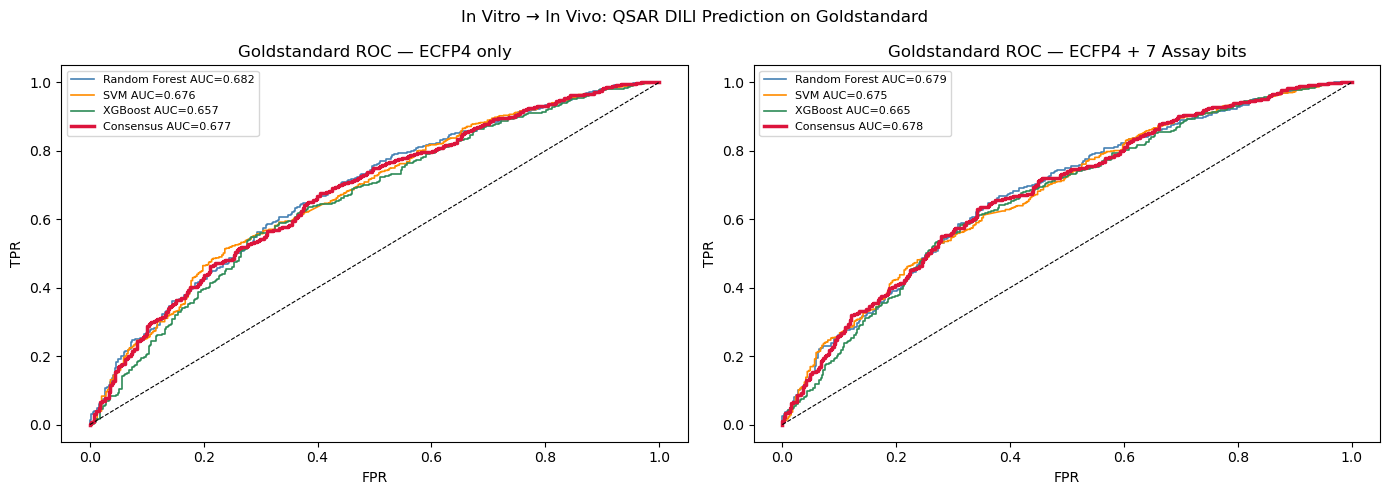

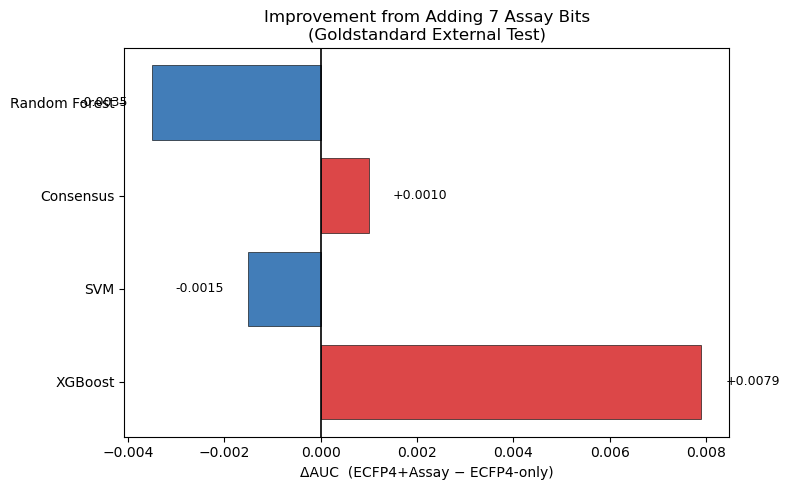

In [25]:
COLORS = {'Random Forest':'steelblue','SVM':'darkorange','XGBoost':'seagreen','Consensus':'crimson'}

# ── Figure 1: ROC on Goldstandard ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, feat_label, X_ex, title in [
    (axes[0], 'ECFP4-only',  X_ecfp_gs, 'Goldstandard ROC — ECFP4 only'),
    (axes[1], 'ECFP4+Assay', X_full_gs, 'Goldstandard ROC — ECFP4 + 7 Assay bits'),
]:
    model_clfs = [
        ('Random Forest', best_rf_ecfp  if 'only' in feat_label else best_rf_full),
        ('SVM',           best_svm_ecfp if 'only' in feat_label else best_svm_full),
        ('XGBoost',       best_xgb_ecfp if 'only' in feat_label else best_xgb_full),
    ]
    probs_list = [c.predict_proba(X_ex)[:,1] for _,c in model_clfs]
    cons_prob  = np.mean(probs_list, axis=0)

    for (name, _), prob in zip(model_clfs, probs_list):
        fpr, tpr, _ = roc_curve(y_gs, prob)
        auc = roc_auc_score(y_gs, prob)
        ax.plot(fpr, tpr, color=COLORS[name], lw=1.2, label=f'{name} AUC={auc:.3f}')
    fpr, tpr, _ = roc_curve(y_gs, cons_prob)
    auc = roc_auc_score(y_gs, cons_prob)
    ax.plot(fpr, tpr, color=COLORS['Consensus'], lw=2.5, label=f'Consensus AUC={auc:.3f}')
    ax.plot([0,1],[0,1],'k--',lw=0.8)
    ax.set_xlabel('FPR'); ax.set_ylabel('TPR')
    ax.set_title(title); ax.legend(fontsize=8)

plt.suptitle('In Vitro → In Vivo: QSAR DILI Prediction on Goldstandard', fontsize=12)
plt.tight_layout()
plt.savefig(f'{BASE}/combined/qsar_dili_roc.png', dpi=200, bbox_inches='tight')
plt.show()

# ── Figure 2: AUC delta (ECFP4+Assay vs ECFP4-only) ─────────────────────────
ext05 = df_ext[df_ext.CPT==0.5].copy()
pivot = ext05.pivot_table(index='Model', columns='Features', values='ROC-AUC')
pivot['Delta AUC'] = pivot['ECFP4+Assay'] - pivot['ECFP4-only']
pivot = pivot.sort_values('ECFP4+Assay', ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
colors = ['#d62728' if v > 0 else '#2166ac' for v in pivot['Delta AUC']]
bars = ax.barh(pivot.index, pivot['Delta AUC'], color=colors, alpha=0.85, edgecolor='k', lw=0.5)
ax.axvline(0, color='black', lw=1.2)
for bar, v in zip(bars, pivot['Delta AUC']):
    ax.text(v + (0.0005 if v >= 0 else -0.0005), bar.get_y()+bar.get_height()/2,
            f'{v:+.4f}', va='center', ha='left' if v>=0 else 'right', fontsize=9)
ax.set_xlabel('ΔAUC  (ECFP4+Assay − ECFP4-only)')
ax.set_title('Improvement from Adding 7 Assay Bits\n(Goldstandard External Test)')
plt.tight_layout()
plt.savefig(f'{BASE}/combined/qsar_dili_delta_auc.png', dpi=200, bbox_inches='tight')
plt.show()


---
## Step 9 — Final Summary Table

FINAL RANKING — DILI Prediction on Goldstandard (CPT=0.5)
Training: Alloriginaldata 12,900 | External test: DILI Goldstandard 1,096


CPT  Sensitivity  Specificity   CCR  ROC-AUC  \
Model         Features                                                    
Random Forest ECFP4-only   0.5         65.3         60.6  62.9   0.6820   
              ECFP4+Assay  0.5         64.4         63.9  64.2   0.6785   
Consensus     ECFP4+Assay  0.5         64.0         63.7  63.8   0.6781   
              ECFP4-only   0.5         64.8         61.6  63.2   0.6771   
SVM           ECFP4-only   0.5         64.3         59.3  61.8   0.6760   
              ECFP4+Assay  0.5         62.4         61.3  61.9   0.6745   
XGBoost       ECFP4+Assay  0.5         64.8         59.8  62.3   0.6650   
              ECFP4-only   0.5         65.8         55.9  60.9   0.6571   

                               AP  
Model         Features             
Random Forest ECFP4-only   0.7850  
              ECFP4+Assay  0.7803  
Consensus     ECFP4+Assay  0.7770  
              ECFP4-only   0.7750  
SVM           ECFP4-only   0.7717  
              ECFP4+Assay  0.7749  
XGBoost       ECFP4+Assay  0.7620  
              ECFP4-only   0.7514


=== Feature Importance — Top 20 bits (RF, ECFP4+Assay model) ===
Assay bits in top 20: 1
  Bit 2048 (Mito (AID_720635)): importance=0.034751


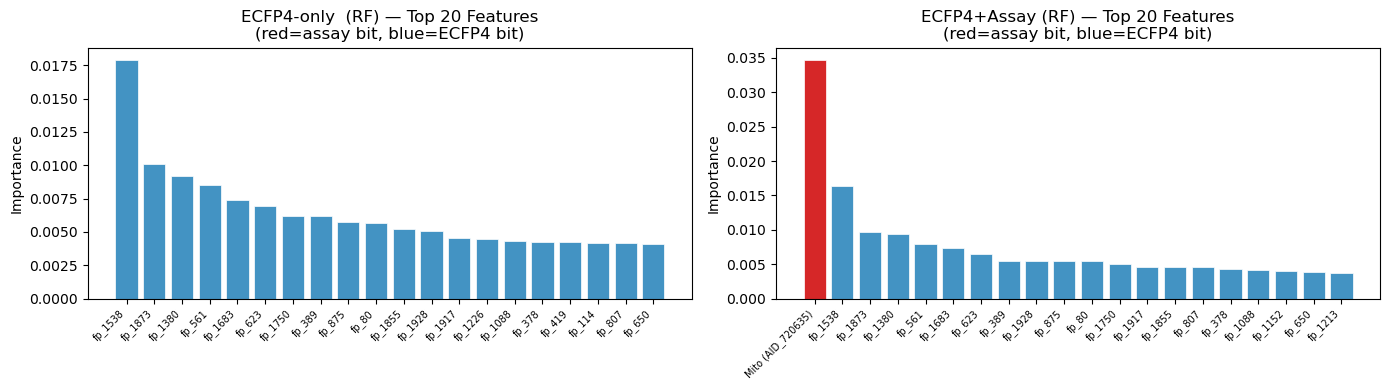


All done. Saved: qsar_dili_roc.png, qsar_dili_delta_auc.png, qsar_dili_feature_importance.png


In [26]:
print('='*90)
print('FINAL RANKING — DILI Prediction on Goldstandard (CPT=0.5)')
print('Training: Alloriginaldata 12,900 | External test: DILI Goldstandard 1,096')
print('='*90)
ext_sorted = df_ext[df_ext.CPT==0.5][METRIC_COLS].sort_values('ROC-AUC', ascending=False)
display(ext_sorted.set_index(['Model','Features']))

print('\n=== Feature Importance — Top 20 bits (RF, ECFP4+Assay model) ===')
imp  = best_rf_full.feature_importances_
top20 = np.argsort(imp)[::-1][:20]
assay_in_top20 = [i for i in top20 if i >= 2048]
print(f'Assay bits in top 20: {len(assay_in_top20)}')
for i in assay_in_top20:
    print(f'  Bit {i} ({assay_names[i-2048]}): importance={imp[i]:.6f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (name, clf, X_te, X_ex) in zip(axes, [
    ('ECFP4-only  (RF)',  best_rf_ecfp, X_ecfp_test, X_ecfp_gs),
    ('ECFP4+Assay (RF)',  best_rf_full, X_full_test, X_full_gs),
]):
    imp = clf.feature_importances_
    top = np.argsort(imp)[::-1][:20]
    colors_ = ['#d62728' if i >= 2048 else '#4393c3' for i in top]
    ax.bar(range(20), imp[top], color=colors_, edgecolor='white', lw=0.5)
    labels_ = [assay_names[i-2048] if i>=2048 else f'fp_{i}' for i in top]
    ax.set_xticks(range(20))
    ax.set_xticklabels(labels_, rotation=45, ha='right', fontsize=7)
    ax.set_title(f'{name} — Top 20 Features\n(red=assay bit, blue=ECFP4 bit)')
    ax.set_ylabel('Importance')

plt.tight_layout()
plt.savefig(f'{BASE}/combined/qsar_dili_feature_importance.png', dpi=200, bbox_inches='tight')
plt.show()
print('\nAll done. Saved: qsar_dili_roc.png, qsar_dili_delta_auc.png, qsar_dili_feature_importance.png')
